# EDA — Phishing vs Legitimate URL (dataset_B_05_2020)
**Mục tiêu:** chạy chuỗi phân tích **Tổng quan → Đơn biến → Hai biến → Đa biến** và *ghi nhận* các lỗi tiềm ẩn lộ ra. Notebook **không loại, không sửa** cột nào; toàn bộ 87 đặc trưng được giữ nguyên để đánh giá các thuật toán chọn đặc trưng. Mỗi lỗi có mã `L#`, tổng hợp ở mục 4.

## 0. Tổng quan

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200, "display.max_columns", 30)

DATA_PATH = "../data/raw/dataset_B_05_2020.csv"   # <- sửa đường dẫn nếu cần
df = pd.read_csv(DATA_PATH)
df["target"] = (df.status == "phishing").astype(int)               # 1 = phishing, 0 = legit
host = df.url.str.extract(r"//([^/:?#]+)")[0]

G = {  # 5 nhóm cột theo dictionary của tác giả
 "URL-cấu trúc": ["ip","https_token","punycode","port","tld_in_path","tld_in_subdomain","abnormal_subdomain","prefix_suffix","random_domain","shortening_service","path_extension","domain_in_brand","brand_in_subdomain","brand_in_path","suspecious_tld","statistical_report"],
 "URL-thống kê": ["length_url","length_hostname","nb_dots","nb_hyphens","nb_at","nb_qm","nb_and","nb_or","nb_eq","nb_underscore","nb_tilde","nb_percent","nb_slash","nb_star","nb_colon","nb_comma","nb_semicolumn","nb_dollar","nb_space","nb_www","nb_com","http_in_path","nb_dslash","ratio_digits_url","ratio_digits_host","nb_subdomains","nb_redirection","nb_external_redirection","length_words_raw","char_repeat","shortest_words_raw","shortest_word_host","shortest_word_path","longest_words_raw","longest_word_host","longest_word_path","avg_words_raw","avg_word_host","avg_word_path","phish_hints"],
 "HTML-liên kết": ["nb_hyperlinks","ratio_intHyperlinks","ratio_extHyperlinks","ratio_nullHyperlinks","nb_extCSS","ratio_intRedirection","ratio_extRedirection","ratio_intErrors","ratio_extErrors","external_favicon","links_in_tags","ratio_intMedia","ratio_extMedia"],
 "HTML-nội dung": ["login_form","submit_email","sfh","iframe","popup_window","safe_anchor","onmouseover","right_clic","empty_title","domain_in_title","domain_with_copyright"],
 "Tra cứu ngoài": ["whois_registered_domain","domain_registration_length","domain_age","web_traffic","dns_record","google_index","page_rank"],
}
GROUP = {c: g for g, v in G.items() for c in v}
feat = list(GROUP); assert set(feat) == set(df.columns) - {"url","status","target"}
X = df[feat]

fe = df[feat]; vc = host.value_counts()
display(pd.Series({
  "Số dòng × số đặc trưng": f"{len(df)} × {len(feat)}",
  "Kiểu dữ liệu": str(X.dtypes.value_counts().to_dict()),
  "Ô NaN": int(df.isna().sum().sum()),
  "Nhãn (phishing / legit)": str(df.status.value_counts().to_dict()),
  "Dòng trùng toàn bộ": int(df.duplicated().sum()),
  "URL trùng": int(df.url.duplicated().sum()),
  "Dòng trùng đặc trưng (bỏ url)": int(fe.duplicated().sum()),
  "Host duy nhất": int(host.nunique()),
  "Host có >1 URL / số dòng thuộc các host đó": f"{int((vc>1).sum())} / {int(vc[vc>1].sum())} ({vc[vc>1].sum()/len(df):.1%})",
  "Host nhiều URL nhất": f"{vc.index[0]} ({vc.iloc[0]})",
  "Host bị gán cả 2 nhãn": int(df.assign(host=host).groupby("host").status.nunique().gt(1).sum()),
}, name="giá trị").to_frame())

,giá trị
Số dòng × số đặc trưng,11430 × 87
Kiểu dữ liệu,"{dtype('int64'): 74, dtype('float64'): 13}"
Ô NaN,0
Nhãn (phishing / legit),"{'legitimate': 5715, 'phishing': 5715}"
Dòng trùng toàn bộ,0
URL trùng,1
Dòng trùng đặc trưng (bỏ url),174
Host duy nhất,8241
Host có >1 URL / số dòng thuộc các host đó,1007 / 4196 (36.7%)
Host nhiều URL nhất,support-appleld.com.secureupdate.duilawyeryork...


**Phát hiện**
- **L1** Dòng trùng: 174 dòng trùng đặc trưng (1 URL trùng hẳn), không mâu thuẫn nhãn.
- **L2** Host lặp: 1.007 host có >1 URL, chiếm 4.196 dòng (36,7%); 1 host có 214 URL; 8 host mang cả 2 nhãn.

## 1. Đơn biến
### 1.1 Phân loại cột theo số giá trị khác nhau

In [2]:
nu = X.nunique()
kind = pd.cut(nu, [0, 1, 2, 20, np.inf], labels=["hằng số (1)", "nhị phân (2)", "rời rạc (3–20)", "liên tục/đếm (>20)"])
display(pd.DataFrame({"số cột": kind.value_counts().sort_index(),
                      "tên cột": kind.groupby(kind, observed=False).apply(lambda s: ", ".join(s.index))}))

,số cột,tên cột
hằng số (1),6,"nb_or, ratio_nullHyperlinks, ratio_intRedirect..."
nhị phân (2),31,"ip, https_token, punycode, port, tld_in_path, ..."
rời rạc (3–20),19,"statistical_report, nb_dots, nb_at, nb_qm, nb_..."
liên tục/đếm (>20),31,"length_url, length_hostname, nb_hyphens, nb_pe..."


**Phát hiện**
- **L3** 6 cột hằng số (chỉ 1 giá trị): `nb_or`, `ratio_nullHyperlinks`, `ratio_intRedirection`, `ratio_intErrors`, `submit_email`, `sfh`.

### 1.2 Biến nhị phân (31 cột)
Quy tắc `WARNING`: mã hóa khác {0,1} · lưu dạng float · có NaN · có sentinel (−1, −99, −999, 999, 9999...) · gần hằng số (giá trị thiểu số < 1%).

In [3]:
SENT = [-1, -99, -999, -9999, 999, 9999, 99999]
def show(t):
    paint = lambda v: "background-color:#ffd9b3" if v == "WARNING" else "background-color:#d9f2d9"
    st = t.style.format(precision=1); (st.map if hasattr(st, "map") else st.applymap)(paint, subset=["status"])
    print("OK:", int((t.status == "OK").sum()), "| WARNING:", int((t.status == "WARNING").sum())); display(st)

b = nu[nu == 2].index
B = pd.DataFrame({"nhóm": pd.Series(GROUP)[b], "dtype": X[b].dtypes.astype(str),
                  "tập giá trị": [str(sorted(X[c].unique().tolist())) for c in b],
                  "đúng {0,1}": [set(X[c].unique()) == {0, 1} for c in b],
                  "%0": (X[b] == 0).mean()*100, "%1": (X[b] == 1).mean()*100, "%NaN": X[b].isna().mean()*100,
                  "sentinel": [bool(X[c].isin(SENT).any()) for c in b]})
B["%thiểu số"] = B[["%0", "%1"]].min(axis=1); B["n thiểu số"] = (B["%thiểu số"]/100*len(X)).round().astype(int)
def why(r):
    o = []
    if not r["đúng {0,1}"]: o.append("mã hóa ≠ {0,1}")
    if not r["dtype"].startswith("int"): o.append("lưu float")
    if r["%NaN"] > 0: o.append("có NaN")
    if r.sentinel: o.append("có sentinel")
    if r["%thiểu số"] < 1: o.append("gần hằng số (<1%)")
    return "; ".join(o)
B["ghi chú"] = B.apply(why, axis=1); B["status"] = np.where(B["ghi chú"] == "", "OK", "WARNING")
show(B.sort_values("%thiểu số"))

OK: 18 | WARNING: 13


,nhóm,dtype,tập giá trị,"đúng {0,1}",%0,%1,%NaN,sentinel,%thiểu số,n thiểu số,ghi chú,status
path_extension,URL-cấu trúc,int64,"[0, 1]",True,100.0,0.0,0.0,False,0.0,2,gần hằng số (<1%),WARNING
punycode,URL-cấu trúc,int64,"[0, 1]",True,100.0,0.0,0.0,False,0.0,4,gần hằng số (<1%),WARNING
nb_star,URL-thống kê,int64,"[0, 1]",True,99.9,0.1,0.0,False,0.1,8,gần hằng số (<1%),WARNING
onmouseover,HTML-nội dung,int64,"[0, 1]",True,99.9,0.1,0.0,False,0.1,13,gần hằng số (<1%),WARNING
iframe,HTML-nội dung,int64,"[0, 1]",True,99.9,0.1,0.0,False,0.1,15,gần hằng số (<1%),WARNING
right_clic,HTML-nội dung,int64,"[0, 1]",True,99.9,0.1,0.0,False,0.1,16,gần hằng số (<1%),WARNING
port,URL-cấu trúc,int64,"[0, 1]",True,99.8,0.2,0.0,False,0.2,27,gần hằng số (<1%),WARNING
nb_external_redirection,URL-thống kê,int64,"[0, 1]",True,99.7,0.3,0.0,False,0.3,36,gần hằng số (<1%),WARNING
brand_in_subdomain,URL-cấu trúc,int64,"[0, 1]",True,99.6,0.4,0.0,False,0.4,47,gần hằng số (<1%),WARNING
brand_in_path,URL-cấu trúc,int64,"[0, 1]",True,99.5,0.5,0.0,False,0.5,56,gần hằng số (<1%),WARNING


**Phát hiện**
- **L4** 13/31 cột gần hằng số (giá trị thiểu số < 1%, chỉ 2–76 dòng): `path_extension`, `punycode`, `nb_star`, `onmouseover`, `iframe`, `right_clic`, `port`, `nb_external_redirection`, `brand_in_subdomain`, `brand_in_path`, `popup_window`, `nb_dslash`, `nb_tilde`.
- Cả 31 cột đều mã hóa đúng {0,1}, kiểu int, không NaN, không sentinel. Lỗi ngữ nghĩa của cột nhị phân (đảo nghĩa, sai định nghĩa) **không thể thấy ở đơn biến**, xem mục 2.

### 1.3 Biến rời rạc (19 cột, 3–20 giá trị)
Quy tắc `WARNING`: có giá trị âm · có NaN · có sentinel · không phải số nguyên · cột "cờ" (nhóm URL-cấu trúc) nhưng > 2 giá trị · giá trị chủ đạo ≥ 99% · nhóm HTML/tra cứu ngoài có ≥ 10% số 0.

In [4]:
d = nu[(nu > 2) & (nu <= 20)].index
D = pd.DataFrame({"nhóm": pd.Series(GROUP)[d], "unique": nu[d],
                  "tập giá trị": [str(sorted(X[c].unique().tolist())) if nu[c] <= 6 else f"{X[c].min():g}–{X[c].max():g}" for c in d],
                  "min": X[d].min(), "max": X[d].max(), "%âm": (X[d] < 0).mean()*100, "%0": (X[d] == 0).mean()*100,
                  "chủ đạo": X[d].apply(lambda s: s.value_counts().index[0]), "%chủ đạo": X[d].apply(lambda s: s.value_counts(normalize=True).iloc[0])*100,
                  "%NaN": X[d].isna().mean()*100, "sentinel": [bool(X[c].isin(SENT).any()) for c in d],
                  "số nguyên": [bool((X[c] % 1 == 0).all()) for c in d]})
zero_sensitive = D.nhóm.isin(["HTML-liên kết", "HTML-nội dung", "Tra cứu ngoài"])
def why(r):
    o = []
    if r["%âm"] > 0: o.append("có giá trị âm")
    if r["%NaN"] > 0: o.append("có NaN")
    if r.sentinel: o.append("có sentinel")
    if not r["số nguyên"]: o.append("không nguyên")
    if r["nhóm"] == "URL-cấu trúc": o.append("cờ có >2 giá trị")
    if r["%chủ đạo"] >= 99: o.append("gần hằng số (≥99%)")
    if r["nhóm"] in ("HTML-liên kết", "HTML-nội dung", "Tra cứu ngoài") and r["%0"] >= 10: o.append("nhiều số 0 (nghi thiếu)")
    return "; ".join(o)
D["ghi chú"] = D.apply(why, axis=1); D["status"] = np.where(D["ghi chú"] == "", "OK", "WARNING")
show(D.sort_values(["status", "%chủ đạo"], ascending=[False, False]))

OK: 15 | WARNING: 4


,nhóm,unique,tập giá trị,min,max,%âm,%0,chủ đạo,%chủ đạo,%NaN,sentinel,số nguyên,ghi chú,status
nb_dollar,URL-thống kê,5,"[0, 1, 2, 3, 6]",0,6,0.0,99.9,0,99.9,0.0,False,True,gần hằng số (≥99%),WARNING
nb_comma,URL-thống kê,5,"[0, 1, 2, 3, 4]",0,4,0.0,99.8,0,99.8,0.0,False,True,gần hằng số (≥99%),WARNING
statistical_report,URL-cấu trúc,3,"[0, 1, 2]",0,2,0.0,96.7,0,96.7,0.0,False,True,cờ có >2 giá trị,WARNING
page_rank,Tra cứu ngoài,11,0–10,0,10,0.0,23.3,0,23.3,0.0,False,True,nhiều số 0 (nghi thiếu),WARNING
http_in_path,URL-thống kê,5,"[0, 1, 2, 3, 4]",0,4,0.0,98.7,0,98.7,0.0,False,True,,OK
nb_colon,URL-thống kê,6,"[1, 2, 3, 4, 5, 7]",1,7,0.0,0.0,1,98.3,0.0,False,True,,OK
nb_space,URL-thống kê,9,0–18,0,18,0.0,98.2,0,98.2,0.0,False,True,,OK
nb_at,URL-thống kê,5,"[0, 1, 2, 3, 4]",0,4,0.0,97.9,0,97.9,0.0,False,True,,OK
nb_semicolumn,URL-thống kê,15,0–20,0,20,0.0,97.8,0,97.8,0.0,False,True,,OK
nb_and,URL-thống kê,15,0–19,0,19,0.0,93.3,0,93.3,0.0,False,True,,OK


**Phát hiện**
- **L5** `statistical_report` có 3 giá trị {0,1,2} dù thuộc nhóm cờ (96,7% = 0).
- **L6** `nb_dollar` (99,9%) và `nb_comma` (99,8%) gần hằng số.
- **L7** `page_rank` có 23,3% = 0: số 0 vừa có thể là hạng thấp nhất, vừa có thể là "không có dữ liệu".
- 19 cột đều là số nguyên, không âm, không NaN, không sentinel.

### 1.4 Biến liên tục (31 cột, > 20 giá trị)
Quy tắc `WARNING`: có giá trị âm · có NaN · có sentinel · cột tỷ lệ có max > 1 (thang ≠ 0–1) · nhóm HTML/tra cứu ngoài có ≥ 10% số 0 · |skew| ≥ 10 · đuôi cực đoan (max / P99 ≥ 10).

OK: 13 | WARNING: 18


,nhóm,min,P50,P99,max,mean,std,skew,kurt,%âm,%0,%NaN,%ngoại lai (3×IQR),số nguyên,sentinel,max/P99,ghi chú,status
nb_percent,URL-thống kê,0.0,0.0,3.7,96.0,0.1,1.5,35.4,1872.4,0.0,96.9,0.0,3.1,True,False,25.9,lệch rất mạnh; đuôi cực đoan,WARNING
nb_extCSS,HTML-liên kết,0.0,0.0,9.0,124.0,0.8,2.8,23.5,887.3,0.0,68.5,0.0,3.4,True,False,13.8,nhiều số 0 (nghi thiếu); lệch rất mạnh; đuôi cực đoan,WARNING
char_repeat,URL-thống kê,0.0,3.0,15.0,146.0,2.9,4.8,15.8,393.8,0.0,20.7,0.0,1.2,True,False,9.7,lệch rất mạnh,WARNING
longest_words_raw,URL-thống kê,2.0,11.0,80.0,829.0,15.4,22.1,13.5,294.8,0.0,0.0,0.0,3.8,True,False,10.4,lệch rất mạnh; đuôi cực đoan,WARNING
avg_word_path,URL-thống kê,0.0,4.9,26.4,250.0,5.1,7.1,13.4,336.1,0.0,28.1,0.0,1.0,False,False,9.5,lệch rất mạnh,WARNING
longest_word_path,URL-thống kê,0.0,7.0,80.0,829.0,10.6,23.1,12.4,256.9,0.0,28.1,0.0,2.6,True,False,10.4,lệch rất mạnh; đuôi cực đoan,WARNING
domain_registration_length,Tra cứu ngoài,-1.0,242.0,3285.6,29829.0,492.5,814.8,9.8,294.7,0.4,12.3,0.0,8.6,True,True,9.1,có giá trị âm; có sentinel; nhiều số 0 (nghi thiếu),WARNING
nb_hyperlinks,HTML-liên kết,0.0,34.0,747.0,4659.0,87.2,166.8,7.7,118.0,0.0,12.1,0.0,4.0,True,False,6.2,nhiều số 0 (nghi thiếu),WARNING
ratio_extErrors,HTML-liên kết,0.0,0.0,0.8,1.0,0.1,0.2,3.5,13.6,0.0,71.0,0.0,14.0,False,False,1.3,nhiều số 0 (nghi thiếu),WARNING
web_traffic,Tra cứu ngoài,0.0,1651.0,9390428.0,10767986.0,856756.6,1995606.0,2.8,7.3,0.0,38.9,0.0,15.4,True,False,1.1,nhiều số 0 (nghi thiếu),WARNING


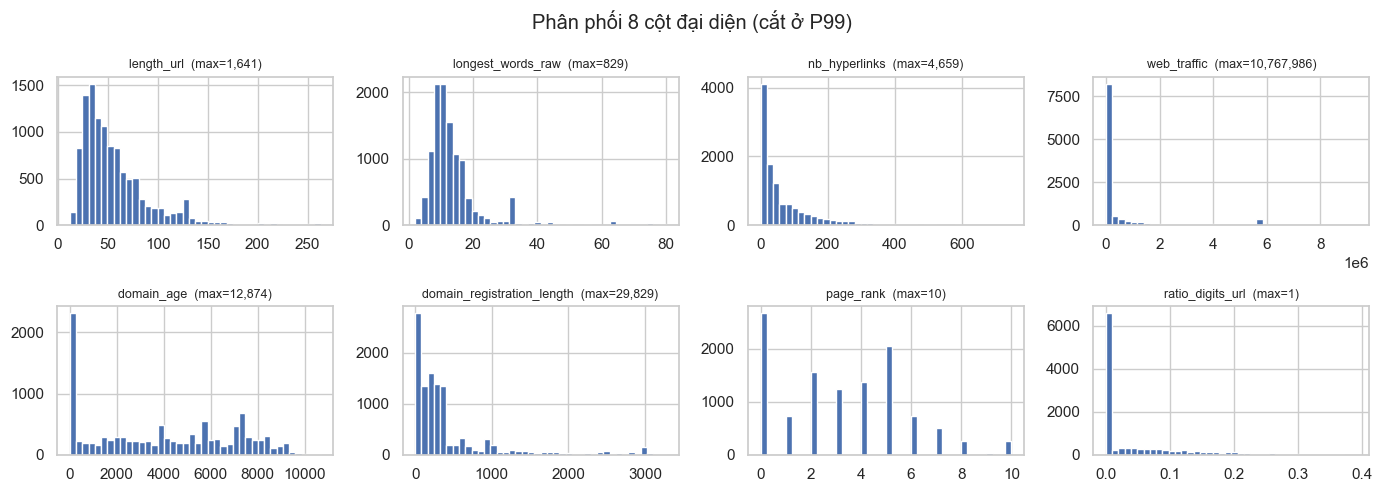

In [5]:
c = nu[nu > 20].index
q1, q3 = X[c].quantile(.25), X[c].quantile(.75); iqr = q3 - q1
C = pd.DataFrame({"nhóm": pd.Series(GROUP)[c], "min": X[c].min(), "P50": X[c].median(), "P99": X[c].quantile(.99), "max": X[c].max(),
                  "mean": X[c].mean(), "std": X[c].std(), "skew": X[c].skew(), "kurt": X[c].kurt(),
                  "%âm": (X[c] < 0).mean()*100, "%0": (X[c] == 0).mean()*100, "%NaN": X[c].isna().mean()*100,
                  "%ngoại lai (3×IQR)": ((X[c] > q3 + 3*iqr) | (X[c] < q1 - 3*iqr)).mean()*100,
                  "số nguyên": [bool((X[k] % 1 == 0).all()) for k in c], "sentinel": [bool(X[k].isin(SENT).any()) for k in c]})
C["max/P99"] = C["max"] / C["P99"].replace(0, np.nan)
ratio_like = pd.Series([k.startswith("ratio") or k in ("links_in_tags", "safe_anchor") for k in c], index=c)
def why(r):
    o = []
    if r["%âm"] > 0: o.append("có giá trị âm")
    if r["%NaN"] > 0: o.append("có NaN")
    if r.sentinel: o.append("có sentinel")
    if ratio_like[r.name] and r["max"] > 1: o.append(f"tỷ lệ có max={r['max']:g} (thang ≠ 0–1)")
    if r["nhóm"] in ("HTML-liên kết", "HTML-nội dung", "Tra cứu ngoài") and r["%0"] >= 10: o.append("nhiều số 0 (nghi thiếu)")
    if abs(r["skew"]) >= 10: o.append("lệch rất mạnh")
    if r["max/P99"] >= 10: o.append("đuôi cực đoan")
    return "; ".join(o)
C["ghi chú"] = C.apply(why, axis=1); C["status"] = np.where(C["ghi chú"] == "", "OK", "WARNING")
show(C.sort_values(["status", "skew"], ascending=[False, False]))

rep = ["length_url", "longest_words_raw", "nb_hyperlinks", "web_traffic", "domain_age", "domain_registration_length", "page_rank", "ratio_digits_url"]
fig, ax = plt.subplots(2, 4, figsize=(14, 5))
for a, k in zip(ax.ravel(), rep):
    v = X[k]; a.hist(v[v <= v.quantile(.99)], bins=40, color="#4C72B0"); a.set_title(f"{k}  (max={v.max():,.0f})", fontsize=9)
plt.suptitle("Phân phối 8 cột đại diện (cắt ở P99)"); plt.tight_layout(); plt.show()

**Phát hiện**
- **L8** Giá trị âm / sentinel: `domain_age` âm ở 1.837 dòng (16,1%), trong đó 1.781 dòng = −1 (mã hóa thiếu), min −12; `domain_registration_length` có 46 dòng = −1.
- **L9** Thang tỷ lệ không đồng nhất: `links_in_tags`, `safe_anchor`, `ratio_intMedia`, `ratio_extMedia` chạy 0–100, trong khi các `ratio_*` khác 0–1; `ratio_extRedirection` có max = 2.
- **L10** 12 cột nhóm HTML/tra cứu ngoài có ≥ 10% số 0: `web_traffic` 38,9%, `nb_hyperlinks` 12,1%, `domain_registration_length` 12,3%, `ratio_extErrors` 71,0%, `nb_extCSS` 68,5%, `ratio_extMedia` 64,2%, `ratio_extRedirection` 53,7%, `ratio_intMedia` 47,8%, `safe_anchor` 38,8%, `links_in_tags` 29,8%, `ratio_extHyperlinks` 26,9%, `ratio_intHyperlinks` 16,5%. Histogram cho thấy cột cao bất thường tại 0/âm ở `domain_age`, `web_traffic`, `domain_registration_length`.
- **L11** 26/31 cột |skew| ≥ 1; 6 cột skew ≥ 10 (`nb_percent` 35,4, `nb_extCSS` 23,5, `char_repeat` 15,8, `longest_words_raw` 13,5, `avg_word_path` 13,4, `longest_word_path` 12,4); 4 cột có max ≥ 10×P99. Cực đoan: `length_url` max 1.641, `web_traffic` max ~10,8 triệu.
- **L12** `domain_registration_length` trung vị 242, max 29.829: nếu đơn vị là năm (theo dictionary) thì phi thực tế → nhiều khả năng đơn vị là **ngày**.

## 2. Hai biến
### 2.1 Cột đặc trưng vs chính URL (tái tạo lại từ chuỗi URL)

In [6]:
u = df.url; body = u.str.replace(r"^https?://", "", regex=True); path = u.str.extract(r"//[^/]+(/.*)?$")[0].fillna("")
cnt = lambda ch: u.str.count(ch)
rc = {"length_url": u.str.len(), "length_hostname": host.str.len(), "nb_dots": cnt(r"\."), "nb_hyphens": cnt("-"), "nb_at": cnt("@"),
      "nb_qm": cnt(r"\?"), "nb_and": cnt("&"), "nb_eq": cnt("="), "nb_underscore": cnt("_"), "nb_percent": cnt("%"), "nb_slash": cnt("/"),
      "nb_colon": cnt(":"), "nb_semicolumn": cnt(";"), "nb_space": cnt(" ") + cnt("%20"), "nb_www": cnt("www"), "nb_com": cnt(r"\.com"),
      "nb_tilde": cnt("~"), "nb_star": cnt(r"\*"), "nb_comma": cnt(","), "nb_dollar": cnt(r"\$"), "nb_dslash": body.str.count("//"),
      "http_in_path": path.str.contains("http").astype(int), "https_token": u.str.startswith("https").astype(int),
      "ip": host.str.fullmatch(r"\d{1,3}(\.\d{1,3}){3}").fillna(False).astype(int)}
r = pd.DataFrame({c: {"% dòng lệch": (X[c] != v).mean()*100, "corr": np.corrcoef(X[c], v)[0, 1]} for c, v in rc.items()}).T
display(r.sort_values("% dòng lệch").round(2).T)
print("ip=1:", int(X.ip.sum()), "| host thực sự là IPv4:", int(rc["ip"].sum()))

,length_hostname,nb_hyphens,nb_qm,nb_at,nb_and,nb_eq,nb_percent,nb_underscore,nb_semicolumn,nb_colon,nb_slash,nb_star,nb_comma,nb_dollar,nb_dots,nb_www,nb_space,nb_tilde,length_url,nb_dslash,http_in_path,ip,nb_com,https_token
% dòng lệch,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.02,0.02,0.02,0.05,0.12,0.18,14.23,62.90,100.0
corr,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,0.99,1.00,0.84,0.86,0.22,0.45,-1.0


ip=1: 1721 | host thực sự là IPv4: 97


**Phát hiện**
- Đã tái tạo 24 cột từ URL: 21 cột khớp ≥ 99,8% → bước trích đặc trưng từ URL đáng tin.
- **L13** `https_token` lệch 100%, corr = −1 → **giá trị bị đảo** (1 = URL *không* dùng https).
- **L14** `ip` lệch 14,2%, corr chỉ 0,22: 1.721 dòng bằng 1 nhưng chỉ 97 URL có host là IPv4 → cột **không đo đúng định nghĩa**.
- **L15** `nb_com` lệch 62,9% với mọi cách đếm thử → **không tái lập được** (cần đối chiếu mã nguồn tác giả).

### 2.2 Cột vs cột
**(a) Cặp cột có tổng cố định / (b) Cấu trúc số 0 theo dòng của khối HTML**

[(a)] ratio_intHyperlinks + ratio_extHyperlinks = 1 ở mọi trang sống (10049 dòng)
[(b)] 14/19 cột HTML luôn = 0 khi nb_hyperlinks = 0 | dòng bằng 0 trên cả 14 cột: 1381 (nb_hyperlinks=0: 1381; trong đó trang sống: 0)
[(b)] cột HTML còn lại ở trang chết, P(=1): {'popup_window': np.float64(0.0), 'safe_anchor': np.float64(0.14), 'empty_title': np.float64(0.83), 'domain_in_title': np.float64(0.97), 'domain_with_copyright': np.float64(0.18)}


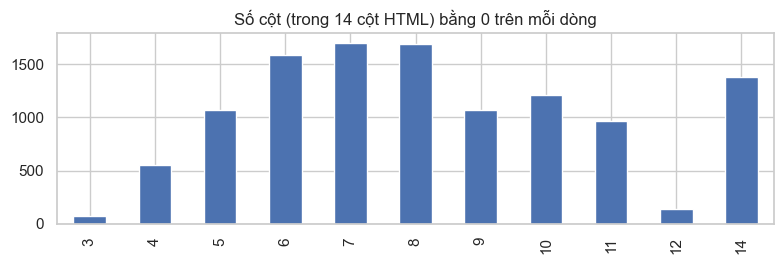

In [7]:
live = X.nb_hyperlinks > 0
rcols = [k for k in nu[nu > 2].index if (k.startswith("ratio") or k in ("links_in_tags", "safe_anchor")) and X.loc[live, k].max() <= 100]
import itertools
for a, b in itertools.combinations(rcols, 2):
    sm = X.loc[live, a] + X.loc[live, b]
    if sm.std() < 1e-6: print(f"[(a)] {a} + {b} = {sm.iloc[0]:.0f} ở mọi trang sống ({int(live.sum())} dòng)")

html = [c for c in G["HTML-liên kết"] + G["HTML-nội dung"] if nu[c] > 1]
zc = [c for c in html if (X.loc[~live, c] == 0).all()]          # cột HTML luôn = 0 khi nb_hyperlinks = 0
z = (X[zc] == 0).sum(axis=1)
print(f"[(b)] {len(zc)}/{len(html)} cột HTML luôn = 0 khi nb_hyperlinks = 0 | dòng bằng 0 trên cả {len(zc)} cột: {int((z == len(zc)).sum())} (nb_hyperlinks=0: {int((~live).sum())}; trong đó trang sống: {int(((z == len(zc)) & live).sum())})")
print("[(b)] cột HTML còn lại ở trang chết, P(=1):", {c: round(X.loc[~live, c].mean(), 2) for c in html if c not in zc})
z.value_counts().sort_index().plot.bar(figsize=(8, 2.8), color="#4C72B0"); plt.title(f"Số cột (trong {len(zc)} cột HTML) bằng 0 trên mỗi dòng"); plt.xlabel(""); plt.tight_layout(); plt.show()

**(c) Cột nhị phân phản ứng thế nào khi một cột "nguồn" nhận giá trị bất thường (L8, L10)**

In [8]:
bins = [c for c in nu[nu == 2].index]
ind = {"trang chết (nb_hyperlinks=0)": ~live, "domain_age<0": X.domain_age < 0, "web_traffic=0": X.web_traffic == 0}
rows = []
for k, m in ind.items():
    d = pd.DataFrame({"P(=1) khi có": X.loc[m, bins].mean()*100, "P(=1) khi không": X.loc[~m, bins].mean()*100})
    d["Δ"] = d.iloc[:, 0] - d.iloc[:, 1]
    d = d.reindex(d.Δ.abs().sort_values(ascending=False).index).head(6); d.insert(0, "điều kiện", k); rows.append(d)
display(pd.concat(rows).round(1))

,điều kiện,P(=1) khi có,P(=1) khi không,Δ
empty_title,trang chết (nb_hyperlinks=0),82.8,2.8,80.0
external_favicon,trang chết (nb_hyperlinks=0),0.0,50.3,-50.3
google_index,trang chết (nb_hyperlinks=0),80.0,49.7,30.3
domain_with_copyright,trang chết (nb_hyperlinks=0),17.5,47.6,-30.1
domain_in_title,trang chết (nb_hyperlinks=0),97.4,74.9,22.5
https_token,trang chết (nb_hyperlinks=0),75.8,59.1,16.7
whois_registered_domain,domain_age<0,32.1,2.5,29.5
domain_in_brand,domain_age<0,0.5,12.3,-11.8
random_domain,domain_age<0,16.3,6.8,9.5
external_favicon,domain_age<0,36.5,45.7,-9.2


**Phát hiện**
- **L16** `ratio_intHyperlinks` + `ratio_extHyperlinks` = 1 ở mọi trang sống → hai cột **bù nhau tuyệt đối** (dư thừa hoàn toàn).
- **L17** Khối HTML "chết đồng loạt": 14/19 cột HTML luôn = 0 khi `nb_hyperlinks = 0`; 1.381 dòng bằng 0 trên cả 14 cột, và 0 dòng như vậy ở trang sống → đây là **trang không tải được**, các số 0 là giả (liên quan L10). Các cột còn lại bị kéo lệch theo (vd `empty_title` = 1 ở 82,8% trang chết so với 2,8%).
- **L18** Hành vi cột nhị phân ngược logic tên, với `whois_registered_domain`, `google_index`, `domain_in_title`, `dns_record`: khi `domain_age<0` (không có WHOIS) thì `whois_registered_domain` = 1 chiếm 32,1% (so với 2,5%); khi `web_traffic=0` thì `google_index` = 1 chiếm 78,5% (so với 37,4%); khi trang chết thì `domain_in_title` = 1 chiếm 97,4% (so với 74,9%); `dns_record` cũng đổi chiều tương tự (6,5% so với 1,2%) → **ngữ nghĩa các cột này bị đảo** (cùng L13).

**(d) Bất biến logic giữa các cột** (quan hệ phải đúng nếu dữ liệu nhất quán)

In [9]:
inv = {
 "length_hostname ≤ length_url": X.length_hostname <= X.length_url,
 "nb_subdomains ≤ nb_dots": X.nb_subdomains <= X.nb_dots,
 "nb_external_redirection ≤ nb_redirection": X.nb_external_redirection <= X.nb_redirection,
 "nb_slash ≥ nb_dslash": X.nb_slash >= X.nb_dslash,
 "shortest ≤ avg ≤ longest (raw)": (X.shortest_words_raw <= X.avg_words_raw) & (X.avg_words_raw <= X.longest_words_raw),
 "shortest ≤ avg ≤ longest (host)": (X.shortest_word_host <= X.avg_word_host) & (X.avg_word_host <= X.longest_word_host),
 "shortest ≤ avg ≤ longest (path)": (X.shortest_word_path <= X.avg_word_path) & (X.avg_word_path <= X.longest_word_path),
 "longest_word_host ≤ length_hostname": X.longest_word_host <= X.length_hostname,
 "longest_words_raw ≤ length_url": X.longest_words_raw <= X.length_url,
 "length_words_raw ≤ length_url": X.length_words_raw <= X.length_url,
 "char_repeat ≤ length_url": X.char_repeat <= X.length_url,
 "ratio_digits_url ≤ 1": X.ratio_digits_url <= 1, "ratio_digits_host ≤ 1": X.ratio_digits_host <= 1,
 "ratio_extErrors ≤ 1": X.ratio_extErrors <= 1, "ratio_extRedirection ≤ 1": X.ratio_extRedirection <= 1,
 "nb_extCSS ≤ nb_hyperlinks": X.nb_extCSS <= X.nb_hyperlinks,
}
viol = pd.Series({k: int((~v).sum()) for k, v in inv.items()}, name="số dòng vi phạm")
display(viol.to_frame().assign(status=np.where(viol > 0, "WARNING", "OK")))

,số dòng vi phạm,status
length_hostname ≤ length_url,0,OK
nb_subdomains ≤ nb_dots,0,OK
nb_external_redirection ≤ nb_redirection,0,OK
nb_slash ≥ nb_dslash,0,OK
shortest ≤ avg ≤ longest (raw),0,OK
shortest ≤ avg ≤ longest (host),0,OK
shortest ≤ avg ≤ longest (path),0,OK
longest_word_host ≤ length_hostname,0,OK
longest_words_raw ≤ length_url,0,OK
length_words_raw ≤ length_url,0,OK


**Phát hiện**
- **L19** 16 bất biến logic: 14 đạt 100%; vi phạm: `ratio_extRedirection ≤ 1` (50 dòng, trùng L9) và `char_repeat ≤ length_url` (1 dòng).

### 2.3 Cột vs nhãn: tỷ lệ giá trị bất thường theo lớp

,số dòng,% legit,% phishing
domain_age < 0,1837.0,14.8,17.4
domain_registration_length ≤ 0,1450.0,11.8,13.5
web_traffic = 0,4444.0,14.6,63.2
page_rank = 0,2666.0,1.8,44.9
trang chết (nb_hyperlinks = 0),1381.0,5.6,18.6
media: int = ext = 0,3874.0,19.6,48.2


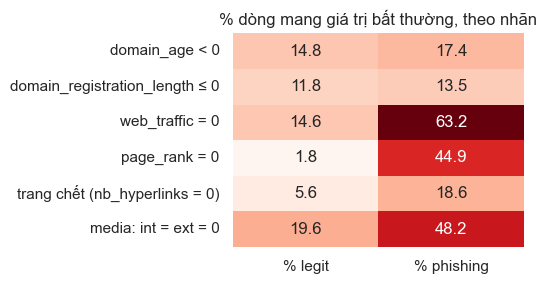

In [10]:
rules = {"domain_age < 0": X.domain_age < 0, "domain_registration_length ≤ 0": X.domain_registration_length <= 0,
         "web_traffic = 0": X.web_traffic == 0, "page_rank = 0": X.page_rank == 0,
         "trang chết (nb_hyperlinks = 0)": ~live, "media: int = ext = 0": (X.ratio_intMedia == 0) & (X.ratio_extMedia == 0)}
miss = pd.DataFrame({k: {"số dòng": int(m.sum()), "% legit": m[df.target == 0].mean()*100, "% phishing": m[df.target == 1].mean()*100} for k, m in rules.items()}).T
display(miss.round(1))
plt.figure(figsize=(5.5, 3)); sns.heatmap(miss[["% legit","% phishing"]], annot=True, fmt=".1f", cmap="Reds", cbar=False)
plt.title("% dòng mang giá trị bất thường, theo nhãn"); plt.tight_layout(); plt.show()

**Phát hiện**
- **L20** Giá trị bất thường **lệch mạnh theo nhãn**: `page_rank=0` 44,9% phishing vs 1,8% legit; `web_traffic=0` 63,2% vs 14,6%; trang chết 18,6% vs 5,6% → việc "thiếu" tự nó mang thông tin nhãn.

## 3. Đa biến
### 3.1 Tương quan giữa các cột (Spearman)

In [11]:
C = X.loc[:, nu > 1].corr(method="spearman").abs()
p = C.where(np.triu(np.ones(C.shape, bool), 1)).stack().rename("|ρ|").reset_index().rename(columns={"level_0": "cột A", "level_1": "cột B"})
display(p[p["|ρ|"] > 0.9].sort_values("|ρ|", ascending=False).round(3).reset_index(drop=True))
print("Số cặp |ρ| > 0.75:", int((p["|ρ|"] > 0.75).sum()))

,cột A,cột B,|ρ|
0,nb_dots,nb_subdomains,0.981
1,longest_word_path,avg_word_path,0.929
2,nb_qm,nb_eq,0.917
3,length_url,length_words_raw,0.908


Số cặp |ρ| > 0.75: 8


### 3.2 Tích lũy tín hiệu bất thường trên mỗi dòng

In [12]:
nflag = sum(m.astype(int) for m in rules.values())
t = df.groupby(nflag).target.agg(["size", "mean"]).rename(columns={"size": "số dòng", "mean": "% phishing"}); t["% phishing"] *= 100
display(t.round(1).T)

,0,1,2,3,4,5,6
số dòng,3980.0,2818.0,2380.0,1261.0,711.0,233.0,47.0
% phishing,16.3,53.1,70.1,79.7,88.3,96.1,100.0


**Phát hiện**
- **L21** Cặp tương quan rất cao (|ρ| > 0,9): `nb_dots`–`nb_subdomains` (0,98), `longest_word_path`–`avg_word_path` (0,93), `nb_qm`–`nb_eq` (0,92), `length_url`–`length_words_raw` (0,91). Riêng cặp `ratio_intHyperlinks`–`ratio_extHyperlinks` (L16) không xuất hiện trong Spearman thô vì bị bóp méo bởi trang chết (L17).
- **L22** Số tín hiệu bất thường trên mỗi dòng tăng thì tỷ lệ phishing tăng mạnh → nhiều lỗi dữ liệu ở trên **cộng gộp thành một tín hiệu nhãn**.

## 4. Tổng hợp lỗi phát hiện
*(Chỉ ghi nhận. Toàn bộ 87 cột được giữ nguyên.)*

| Nhóm lỗi | Mã | Cột liên quan | Bằng chứng chính |
|---|---|---|---|
| Hàng/định danh | L1, L2 | toàn bộ | 174 dòng trùng; 36,7% dòng thuộc host lặp; 8 host 2 nhãn |
| Hằng số / gần hằng số | L3, L4, L6 | 6 cột hằng số; 13 nhị phân; `nb_dollar`, `nb_comma` | 1 giá trị duy nhất; thiểu số < 1% |
| Mã hóa / miền giá trị | L5, L8, L9 | `statistical_report`, `domain_age`, `domain_registration_length`, `links_in_tags`, `safe_anchor`, `ratio_intMedia`, `ratio_extMedia`, `ratio_extRedirection` | 3 giá trị thay vì 0/1; −1 làm sentinel; thang 0–100; ratio max 2 |
| Thiếu ẩn (số 0 giả) | L7, L10, L17 | `page_rank`, `web_traffic`, `nb_hyperlinks` và 9 cột HTML khác | 0 chiếm 12–71%; 1.381 trang không tải được |
| Đơn vị | L12 | `domain_registration_length` | Trung vị 242, max 29.829 (ngày, không phải năm) |
| Phân phối / ngoại lai | L11 | 26 cột liên tục | \|skew\| ≥ 1; 6 cột skew ≥ 10 |
| Ngữ nghĩa đảo / sai | L13, L14, L15, L18 | `https_token`, `google_index`, `domain_in_title`, `whois_registered_domain`, `dns_record`, `ip`, `nb_com` | corr = −1 với URL; `ip` chỉ khớp 97/1.721; `nb_com` không tái lập |
| Bất nhất logic | L19 | `ratio_extRedirection`, `char_repeat` | 50 dòng ratio > 1; 1 dòng char_repeat > length_url |
| Dư thừa | L16, L21 | `ratio_intHyperlinks`/`ratio_extHyperlinks`; 4 cặp \|ρ\| > 0,9 | Tổng = 1; \|ρ\| 0,91–0,98 |
| Liên quan nhãn | L20, L22 | các cột thiếu ẩn | Bất thường lệch mạnh theo nhãn, cộng gộp theo dòng (16% → 100% phishing) |